# CIFAR-10: Data Exploration

A first look at the dataset: 60,000 color images (32×32 pixels) across 10 classes, split into 50,000 training and 10,000 test images.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets

DATA_DIR = Path("../data")  # keeps the dataset out of the notebooks folder
rng = np.random.default_rng(42)  # fixed seed so the same images show each run

In [9]:
import pickle

In [10]:
from pathlib import Path

DATA_DIR = Path("../data/cifar-10-batches-py")


def load_batch(path):
    with open(path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")
    # Each row is 3072 values: 1024 red, then 1024 green, then 1024 blue
    images = (
        batch[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    )  # -> (N, 32, 32, 3)
    labels = np.array(batch[b"labels"])
    return images, labels


def load_cifar10(data_dir):
    train = [load_batch(data_dir / f"data_batch_{i}") for i in range(1, 6)]
    X_train = np.concatenate([x for x, _ in train])
    y_train = np.concatenate([y for _, y in train])

    X_test, y_test = load_batch(data_dir / "test_batch")

    with open(data_dir / "batches.meta", "rb") as f:
        meta = pickle.load(f, encoding="bytes")
    classes = [name.decode() for name in meta[b"label_names"]]

    return X_train, y_train, X_test, y_test, classes


X_train, y_train, X_test, y_test, classes = load_cifar10(DATA_DIR)

print("Train images:", X_train.shape, X_train.dtype)  # (50000, 32, 32, 3) uint8
print("Test images: ", X_test.shape)  # (10000, 32, 32, 3)
print("Classes:     ", classes)

Train images: (50000, 32, 32, 3) uint8
Test images:  (10000, 32, 32, 3)
Classes:      ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


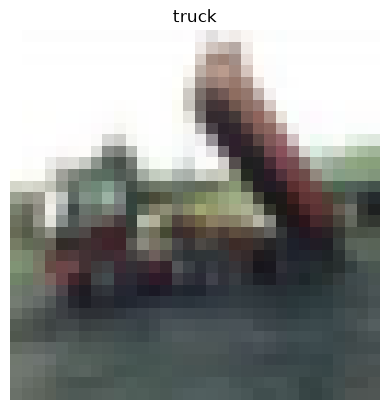

In [11]:
i = 2  # pick any index from 0 to 49999
plt.imshow(X_train[i])
plt.title(classes[y_train[i]])
plt.axis("off")
plt.show()

## Load the dataset

The first run downloads about 170 MB. Later runs reuse the local copy.

In [ ]:
train_set = datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
test_set = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

classes = train_set.classes
X_train, y_train = train_set.data, np.array(train_set.targets)
X_test, y_test = test_set.data, np.array(test_set.targets)

print("Train images:", X_train.shape, X_train.dtype)
print("Test images: ", X_test.shape)
print("Classes:     ", classes)

## Random sample of training images

In [ ]:
idx = rng.choice(len(X_train), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for ax, i in zip(axes.flat, idx):
    ax.imshow(X_train[i])
    ax.set_title(classes[y_train[i]], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Examples from each class

One row per class, which makes it easier to see how varied each class is.

In [ ]:
n_per_class = 10
fig, axes = plt.subplots(len(classes), n_per_class, figsize=(12, 13))

for row, cls in enumerate(classes):
    cls_idx = rng.choice(np.where(y_train == row)[0], size=n_per_class, replace=False)
    for col, i in enumerate(cls_idx):
        ax = axes[row, col]
        ax.imshow(X_train[i])
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

## Class balance

In [ ]:
train_counts = np.bincount(y_train, minlength=len(classes))
test_counts = np.bincount(y_test, minlength=len(classes))

x = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, train_counts, width=0.4, label="train")
ax.bar(x + 0.2, test_counts, width=0.4, label="test")
ax.set_xticks(x, classes, rotation=30)
ax.set_ylabel("images")
ax.set_title("Images per class")
ax.legend()
plt.tight_layout()
plt.show()

for cls, tr, te in zip(classes, train_counts, test_counts):
    print(f"{cls:>10}: {tr:>5} train, {te:>4} test")

## A single image up close

At 32×32, these are very low resolution. Viewing one with no smoothing shows how little detail a model has to work with.

In [ ]:
i = int(rng.integers(len(X_train)))
img = X_train[i]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(img, interpolation="nearest")
axes[0].set_title(f"#{i}: {classes[y_train[i]]}")
for c, (ax, name, cmap) in enumerate(
    zip(axes[1:], ["red", "green", "blue"], ["Reds", "Greens", "Blues"])
):
    ax.imshow(img[:, :, c], cmap=cmap, interpolation="nearest")
    ax.set_title(f"{name} channel")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()